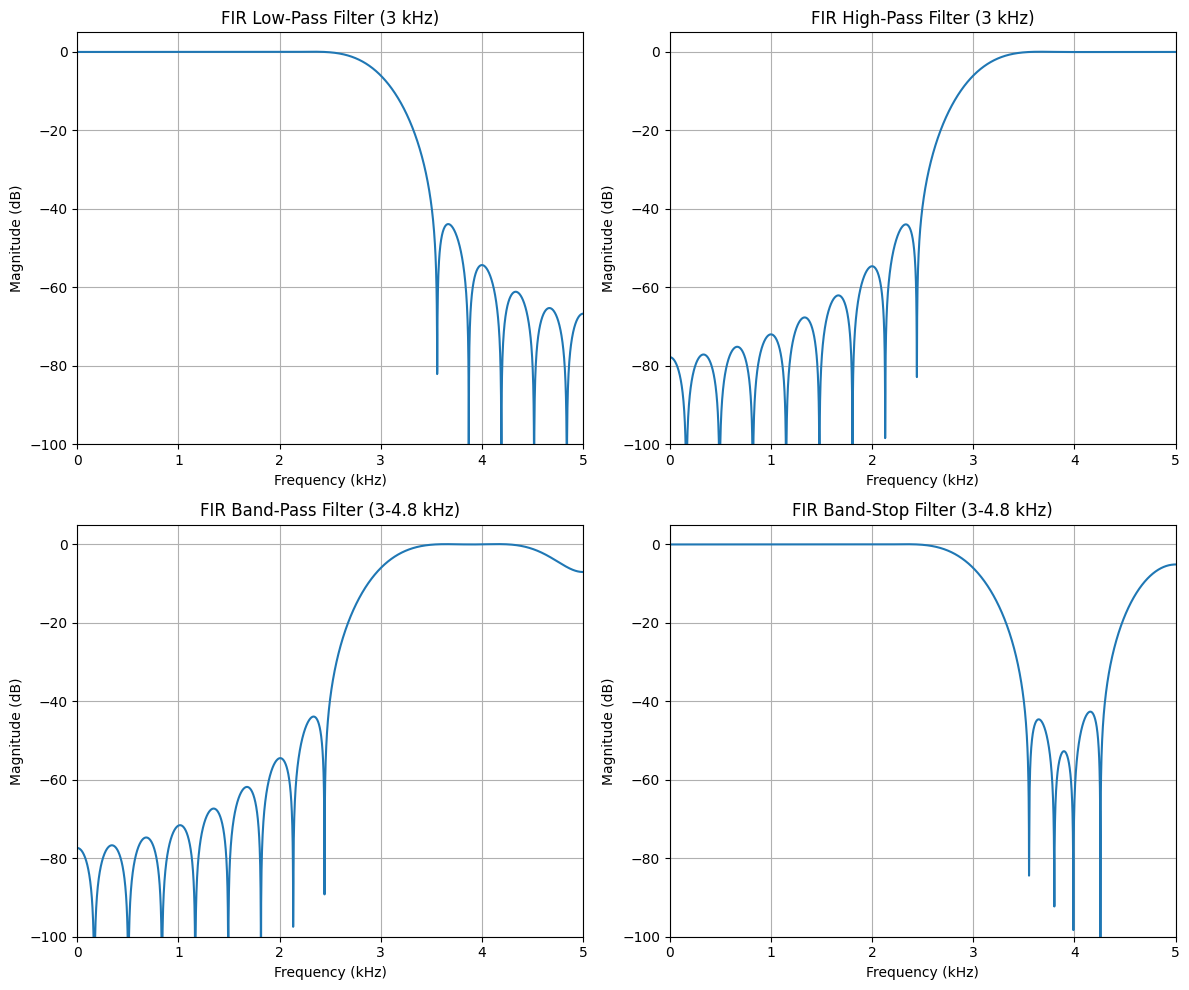

Low-Pass Filter Coefficients:
 [ 0.00000000e+00  2.36294439e-04 -6.22213220e-04 -1.48904646e-03
  4.55351027e-03 -5.84801114e-18 -1.16227064e-02  1.04726495e-02
  1.47629668e-02 -3.30275566e-02  1.75440334e-17  6.31702710e-02
 -5.64178020e-02 -8.95165958e-02  2.99461575e-01  6.00077307e-01
  2.99461575e-01 -8.95165958e-02 -5.64178020e-02  6.31702710e-02
  1.75440334e-17 -3.30275566e-02  1.47629668e-02  1.04726495e-02
 -1.16227064e-02 -5.84801114e-18  4.55351027e-03 -1.48904646e-03
 -6.22213220e-04  2.36294439e-04  0.00000000e+00]

High-Pass Filter Coefficients:
 [ 0.00000000e+00 -2.36155069e-04  6.21846227e-04  1.48816819e-03
 -4.55082453e-03 -3.89637458e-18  1.16158511e-02 -1.04664726e-02
 -1.47542593e-02  3.30080763e-02  1.16891238e-17 -6.31330120e-02
  5.63845257e-02  8.94637973e-02 -2.99284947e-01  3.99815580e-01
 -2.99284947e-01  8.94637973e-02  5.63845257e-02 -6.31330120e-02
  1.16891238e-17  3.30080763e-02 -1.47542593e-02 -1.04664726e-02
  1.16158511e-02 -3.89637458e-18 -4.55082

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, freqz
# Common parameters
Fs = 10000
N = 31
Fc = 3000
# Nyquist frequency
Fn = Fs / 2
# Adjusted upper cutoff for BPF and BSF
F1 = 3000
F2 = 4800
# 1. FIR Low-Pass Filter
lpf = firwin(
    numtaps=N,
    cutoff=Fc,
    window='hann',
    pass_zero='lowpass',
    fs=Fs
)
# 2. FIR High-Pass Filter
hpf = firwin(
    numtaps=N,
    cutoff=Fc,
    window='hann',
    pass_zero='highpass',
    fs=Fs
)
# 3. FIR Band-Pass Filter
bpf = firwin(
    numtaps=N,
    cutoff=[F1, F2],
    window='hann',
    pass_zero='bandpass',
    fs=Fs
)
# 4. FIR Band-Stop Filter
bsf = firwin(
    numtaps=N,
    cutoff=[F1, F2],
    window='hann',
    pass_zero='bandstop',
    fs=Fs
)
# Calculate frequency responses
filters = [
    ("FIR Low-Pass Filter (3 kHz)", lpf),
    ("FIR High-Pass Filter (3 kHz)", hpf),
    ("FIR Band-Pass Filter (3-4.8 kHz)", bpf),
    ("FIR Band-Stop Filter (3-4.8 kHz)", bsf)
]
plt.figure(figsize=(12, 10))
for i, (title, coefficients) in enumerate(filters, start=1):
    f, H = freqz(
        coefficients,
        worN=4096,
        fs=Fs
    )
    magnitude_db = 20 * np.log10(
        np.maximum(np.abs(H), 1e-8)
    )
    plt.subplot(2, 2, i)
    plt.plot(f / 1000, magnitude_db)
    plt.title(title)
    plt.xlabel("Frequency (kHz)")
    plt.ylabel("Magnitude (dB)")
    plt.grid(True)
    plt.xlim(0, Fn / 1000)
    plt.ylim(-100, 5)
plt.tight_layout()
plt.show()
# Print FIR filter coefficients
print("Low-Pass Filter Coefficients:\n", lpf)
print("\nHigh-Pass Filter Coefficients:\n", hpf)
print("\nBand-Pass Filter Coefficients:\n", bpf)
print("\nBand-Stop Filter Coefficients:\n", bsf)